# Évaluation et choix du modèle LLM

SmartCampus AI — Epic SA-30

Ce notebook compare les trois modèles testés selon deux critères principaux :

1. la **latence** ;
2. l'**adaptation à la langue** de l'utilisateur.

Il présente ensuite la qualité des réponses, des exemples concrets et la décision.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results/details.csv")

MODELES = ["gemma4:e2b-it-qat", "qwen3.5:4b", "llama3.2:3b"]
NOMS = {"gemma4:e2b-it-qat": "Gemma 4 E2B", "qwen3.5:4b": "Qwen 3.5 4B", "llama3.2:3b": "Llama 3.2 3B"}
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a"]
LANGUES = {"fr": "Français", "mixte": "Mixte", "arabizi": "Arabizi", "tn_ar": "Tunisien (arabe)"}

df["Modèle"] = df["model"].map(NOMS)
df["Langue"] = df["langue_attendue"].map(LANGUES)
ORDRE = [NOMS[m] for m in MODELES]
print(len(df), "réponses évaluées")
df.groupby(["Modèle", "Langue"]).size().unstack().loc[ORDRE]

180 réponses évaluées


Langue,Arabizi,Français,Mixte,Tunisien (arabe)
Modèle,,,,
Gemma 4 E2B,10,30,10,10
Qwen 3.5 4B,10,30,10,10
Llama 3.2 3B,10,30,10,10


## 1. Modèles comparés et protocole

| Modèle | Éditeur | Taille | Raison du choix |
|---|---|---|---|
| Gemma 4 E2B | Google | ≈ 2,3 Md (Q4) | Conçu pour l'exécution locale, multilingue |
| Qwen 3.5 4B | Alibaba | 4 Md (Q4) | Réputé solide en multilingue et en arabe |
| Llama 3.2 3B | Meta | 3,2 Md (Q4) | Modèle de référence |

- 60 questions : 30 en français (prioritaire) et 30 en dialecte (10 tunisien en arabe, 10 Arabizi, 10 mixte).
- Même prompt pour les trois modèles (zero-shot), même format de sortie JSON, température 0,2 et graine fixe.
- Exécution locale via Ollama, sur un PC portable sans GPU dédié (20 Go de RAM).
- Annotation humaine de chaque réponse : pertinence (1 à 5), registre adapté (0/1), hallucination (0/1).

## 2. Critère 1 — Latence

In [2]:
latence = df.groupby("Modèle")["latence_s"].agg(["mean", "median"]).loc[ORDRE]
latence.columns = ["Latence moyenne (s)", "Latence médiane (s)"]
latence["Requêtes par heure"] = (3600 / latence["Latence moyenne (s)"]).round(0)
latence.round(1)

,Latence moyenne (s),Latence médiane (s),Requêtes par heure
Modèle,,,
Gemma 4 E2B,19.0,17.3,190.0
Qwen 3.5 4B,54.8,55.6,66.0
Llama 3.2 3B,47.2,43.3,76.0


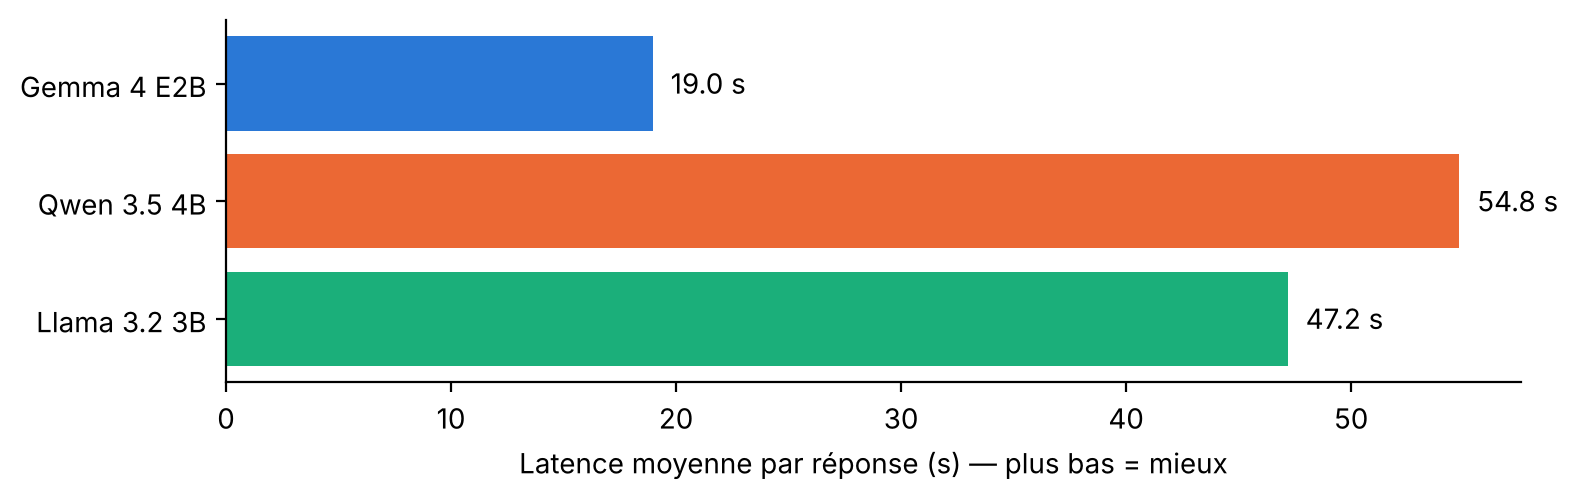

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(ORDRE, latence["Latence moyenne (s)"], color=COULEURS)
for i, v in enumerate(latence["Latence moyenne (s)"]):
    ax.text(v + 0.8, i, f"{v:.1f} s", va="center")
ax.invert_yaxis()
ax.set_xlabel("Latence moyenne par réponse (s) — plus bas = mieux")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

Gemma répond environ trois fois plus vite que Qwen. Pour un chatbot en conversation, c'est déterminant, d'autant plus que les prompts s'allongeront avec la mémoire et les documents.

## 3. Critère 2 — Adaptation à la langue

Deux mesures :

- **a) Registre seul** : le modèle répond dans la langue et le registre de l'utilisateur.
- **b) Registre + réponse compréhensible** : en plus, la réponse est dans la bonne écriture et sa pertinence est d'au moins 3 sur 5.

In [4]:
df["Registre seul"] = df["registre_ok_0_1"] == 1
df["Registre + réponse compréhensible"] = (df["registre_ok_0_1"] == 1) & df["ecriture_ok"] & (df["pertinence_1_5"] >= 3)

mesures = ["Registre seul", "Registre + réponse compréhensible"]
(df.groupby("Modèle")[mesures].mean().loc[ORDRE] * 100).round(0)

,Registre seul,Registre + réponse compréhensible
Modèle,,
Gemma 4 E2B,72.0,67.0
Qwen 3.5 4B,85.0,43.0
Llama 3.2 3B,67.0,23.0


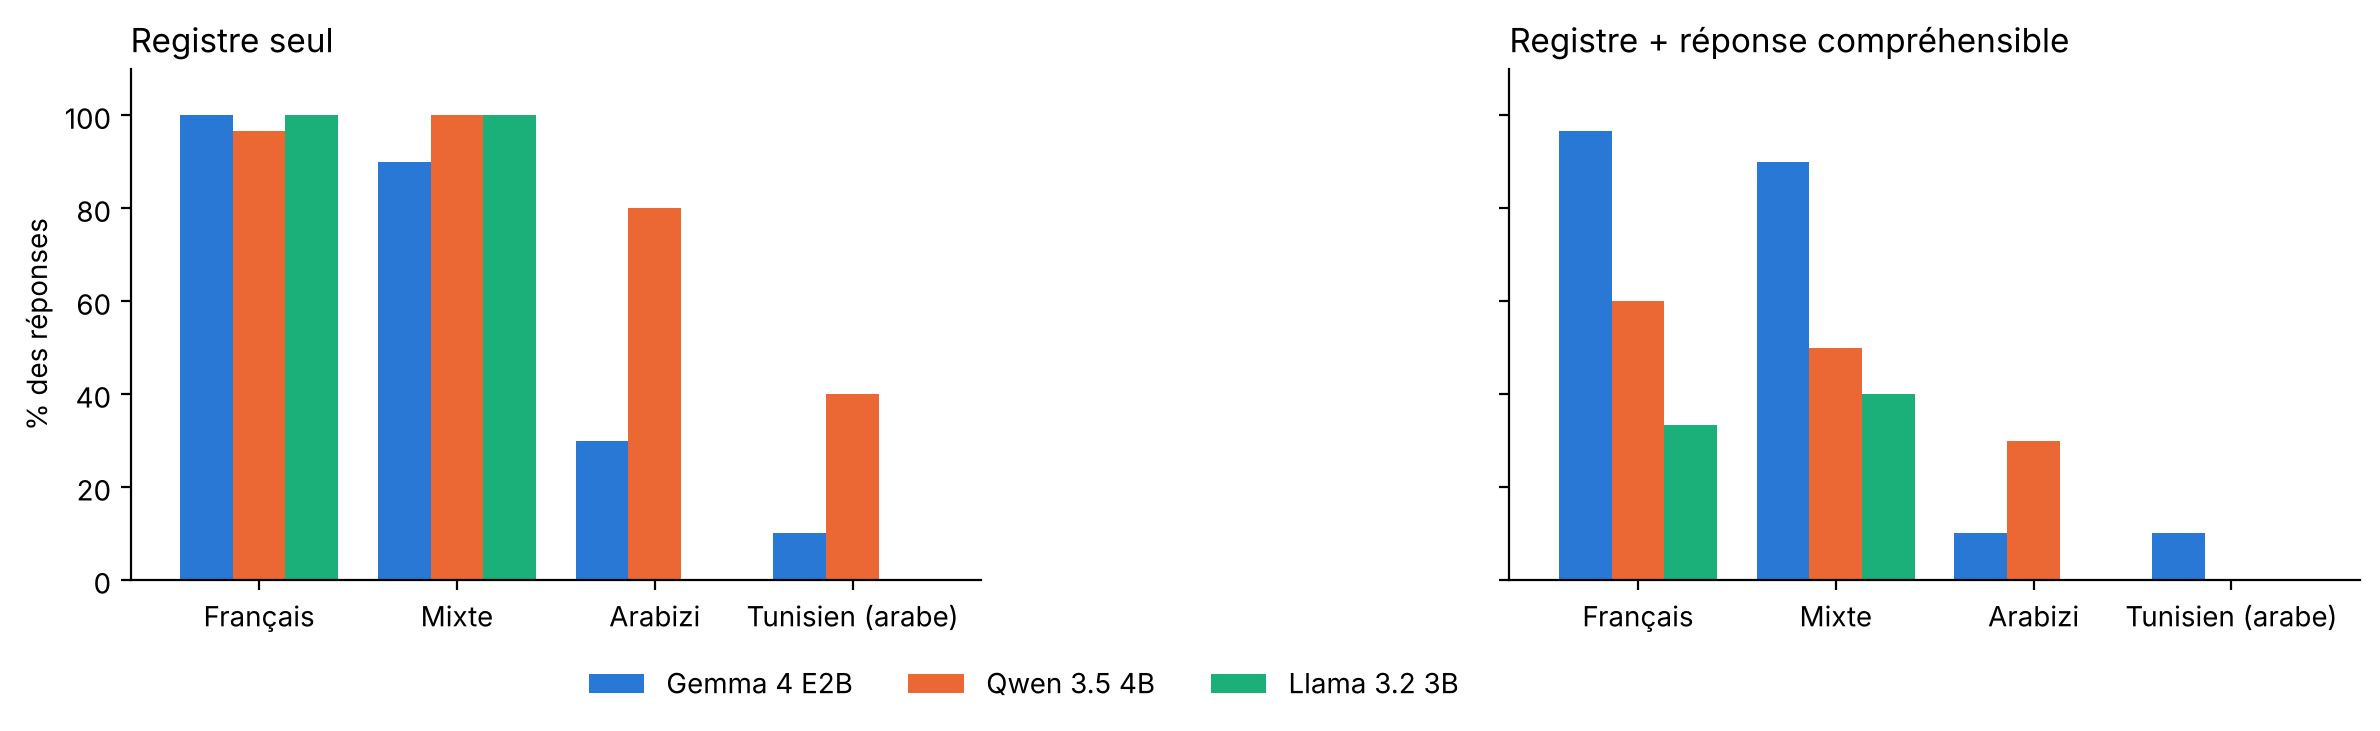

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, m in zip(axs, mesures):
    t = (df.groupby(["Langue", "Modèle"])[m].mean().unstack().loc[list(LANGUES.values()), ORDRE] * 100)
    t.plot.bar(ax=ax, color=COULEURS, width=0.8, rot=0, legend=False)
    ax.set_title(m, loc="left"); ax.set_xlabel(""); ax.set_ylim(0, 110)
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("% des réponses")
axs[0].legend(ORDRE, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(1.05, -0.12))
plt.tight_layout(); plt.show()

Qwen essaie plus souvent de répondre en tunisien ou en Arabizi, mais une grande partie de ces réponses est incohérente. Gemma répond correctement en français et en mixte, mais bascule souvent vers le français ou la darija marocaine face au tunisien. Une réponse dans la bonne langue n'a de valeur que si l'utilisateur la comprend : la mesure b) est retenue.

## 4. Qualité des réponses

In [6]:
qualite = pd.DataFrame({
    "Answer Relevancy (1 à 5)": df.groupby("Modèle")["pertinence_1_5"].mean(),
    "Hallucination Rate (%)": df.groupby("Modèle")["hallucination_0_1"].mean() * 100,
    "Accuracy de l'intention, français (%)": df[df["langue_attendue"] == "fr"].groupby("Modèle")["intention_ok"].mean() * 100,
}).loc[ORDRE]
qualite.round(2)

,Answer Relevancy (1 à 5),Hallucination Rate (%),"Accuracy de l'intention, français (%)"
Modèle,,,
Gemma 4 E2B,3.40,3.33,66.67
Qwen 3.5 4B,2.63,46.67,83.33
Llama 3.2 3B,2.00,38.33,46.67


L'Accuracy mesure uniquement l'étiquette d'intention renvoyée dans le JSON. Qwen classe mieux le type de question, mais ses réponses contiennent une information inventée dans près d'un cas sur deux. Les erreurs d'intention de Gemma sont surtout des confusions entre intentions voisines (comparaison et orientation) et n'empêchent pas une bonne réponse.

## 5. Exemples concrets

In [7]:
pd.set_option("display.max_colwidth", None)
EXEMPLES = ["FR-14", "AZ-04", "FR-16", "AZ-02"]
ex = df[df["id"].isin(EXEMPLES) & df["model"].isin(MODELES[:2])]
ex = ex[["id", "question", "Modèle", "reponse", "pertinence_1_5", "hallucination_0_1", "commentaire"]]
ex.sort_values(["id", "Modèle"]).set_index(["id", "question", "Modèle"])

reponse  \
id    question                                                                                             Modèle                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                
AZ-02 Chnowa el far9 bin prépa w licence?                                                                  Gemma 4 E2B                                                                                                                                                                       Ah, c'est une question importante ! La prépa c'est plus intense et orientée vers les concours, tandis que la licence c'est plus axé sur l'approfondissement d'une matière. Pour te conseiller, il faudrait savoir ce qui te motive le plus. On peut comparer les deux parcours si tu me donnes plus de détails sur tes ambitions.   
                                                                                                           Qwen 3.5 4B                                                                                                                                                                                                                                                                                                                                                 Wahda m3alha l'année de base, wa l'autra t7a9d 2anwa 3la l'ingénierie. L'ingénierie t7a9d 3la l'IT w l'ISB, wa l'prépa t7a9d 3la l'licences classiques.   
AZ-04 9adeh ya5ou wa9t el cycle ingénieur?                                                                 Gemma 4 E2B                                                                                                                                                                                                                                                                                                                                Ahla bik! Cycle ingénieur f l'IIT ykoun 5an. 3andek des questions sur les matières ou les débouchés spécifiques de cette filière ? Je peux t'aider à avoir plus d'infos.   
                                                                                                           Qwen 3.5 4B                                                                                                                                                                                                                                                         Salou, pour le cycle ingénieur à l'IIT, il faut avoir un Bac STI2D ou équivalent avec une moyenne d'au moins 14/20. Les frais sont de 350 dinars par an et la formation dure 3 ans. Tu peux t'inscrire directement si tu as les notes requises.   
FR-14 Est-ce qu'il y a un test ou un entretien pour être admis à l'IIT ?                                   Gemma 4 E2B                                                                                                                                                                                                                  Pour savoir s'il y a un test ou un entretien pour l'IIT, je vais vérifier les informations officielles. Il est important de consulter le site de l'IIT pour connaître les modalités d'admission précises. Je vous conseille de me donner plus de détails sur le niveau que vous visez.   
                                                                                                           Qwen 3.5 4B                                                                                                                                                                                                                   

## 6. Décision

| Critère | Gagnant |
|---|---|
| Latence | Gemma 4 E2B |
| Adaptation à la langue (réponse compréhensible) | Gemma 4 E2B |
| Registre seul | Qwen 3.5 4B |
| Hallucinations | Gemma 4 E2B |

Gemma 4 E2B est retenu : il est le plus rapide, il produit le plus de réponses comprises dans la langue de l'utilisateur et il n'invente presque jamais d'information administrative.

### Points d'amélioration et suite

- Dialecte tunisien : ajouter quelques exemples en tunisien dans le prompt (few-shot). En cas d'incompréhension, le bot demande de reformuler en français.
- Évaluation finale : refaire la comparaison sur le pipeline complet (documents officiels et agent) avec Gemma 4 E2B, Gemma 4 E4B et Qwen 3.5 4B, avec le même prompt pour tous.
- Le backend lit le nom du modèle dans la configuration : changer de modèle ne demande aucune modification du code.